# Non-progressors vs graduates: the earnings gap

How much less do people who leave higher education after first year earn than those who graduate?

| | Non-progressors | Graduates |
|---|---|---|
| Table | **NPO13** (CSO) | **HEO12** Graduate Earnings (CSO) |
| Cohorts | 2018–2023 non-progression year | 2010–2022 graduation year |
| Earnings years | 2019–2024 | 2011–2023 |
| Shared dimensions | gender, NFQ level (6/7/8), years since leaving | gender, NFQ level (6–10), years since graduation, field of study |

**Overlap: earnings years 2019–2023**, NFQ levels 6, 7, 8.

**Two ways to line them up**
1. **Same years since leaving** — non-progressor *k* years after leaving vs graduate *k* years after graduating, in the same calendar year.
   Same labour-market conditions and time in work, but graduates are older and have more years of study.
2. **Same years since starting college** — a Level 8 non-progressor 4 years out vs a Level 8 graduate 1 year out (≈4-year course).
   Same age cohort, roughly; graduates have less work experience. Course lengths assumed: L6 = 2 yrs, L7 = 3 yrs, L8 = 4 yrs.

All euro figures are **constant 2024 euro** (CSO CPA01). Ratios are identical in nominal terms.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
P = ROOT / "data" / "processed"
if not (P / "npo13_tidy.parquet").exists():
    import clean; clean.main()
if not (P / "heo12_tidy.parquet").exists():
    import graduates; graduates.main()
npo = pd.read_parquet(P / "npo13_tidy.parquet")
heo = pd.read_parquet(P / "heo12_tidy.parquet")

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.figsize": (9, 5), "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "ytick.left": False,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
})
EUR = mtick.StrMethodFormatter("€{x:,.0f}")
PCT = mtick.PercentFormatter(1, decimals=0)
LEVELS = ["NFQ Level 6", "NFQ Level 7", "NFQ Level 8"]
COURSE_YEARS = {"NFQ Level 6": 2, "NFQ Level 7": 3, "NFQ Level 8": 4}

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def label_end(ax, x, y, text, dy=0):
    ax.annotate(text, (x, y), xytext=(6, dy), textcoords="offset points", va="center", fontsize=9, color=INK2)

KEY = ["earnings_year", "years_since", "gender", "nfq_level"]
VALS = ["n", "p25_real", "p50_real", "p75_real"]
np_ = npo[(npo.sector == "All sectors") & (npo.outcome == "All outcomes") & (npo.status == "ok")][KEY + VALS]
gr_ = heo[(heo.field == "All fields of education") & (heo.status == "ok")][KEY + VALS]
for d in (np_, gr_):
    for c in ["gender", "nfq_level"]: d[c] = d[c].astype(str)

## 1. Same years since leaving

In [2]:
m = np_.merge(gr_, on=KEY, suffixes=("_np", "_gr"))
m = m[m.nfq_level.isin(LEVELS)]
m["ratio"] = m.p50_real_np / m.p50_real_gr
m["gap_eur"] = m.p50_real_gr - m.p50_real_np
both = m[m.gender == "All genders"]
print("Matched cells:", len(both), "| earnings years", both.earnings_year.min(), "-", both.earnings_year.max())
both.pivot_table(index="years_since", columns="nfq_level", values="ratio").round(2)

Matched cells: 45 | earnings years 2019 - 2023


nfq_level,NFQ Level 6,NFQ Level 7,NFQ Level 8
years_since,,,
1,1.15,0.84,0.65
2,1.00,0.76,0.60
3,0.91,0.76,0.59
4,0.89,0.77,0.60
5,0.82,0.78,0.62


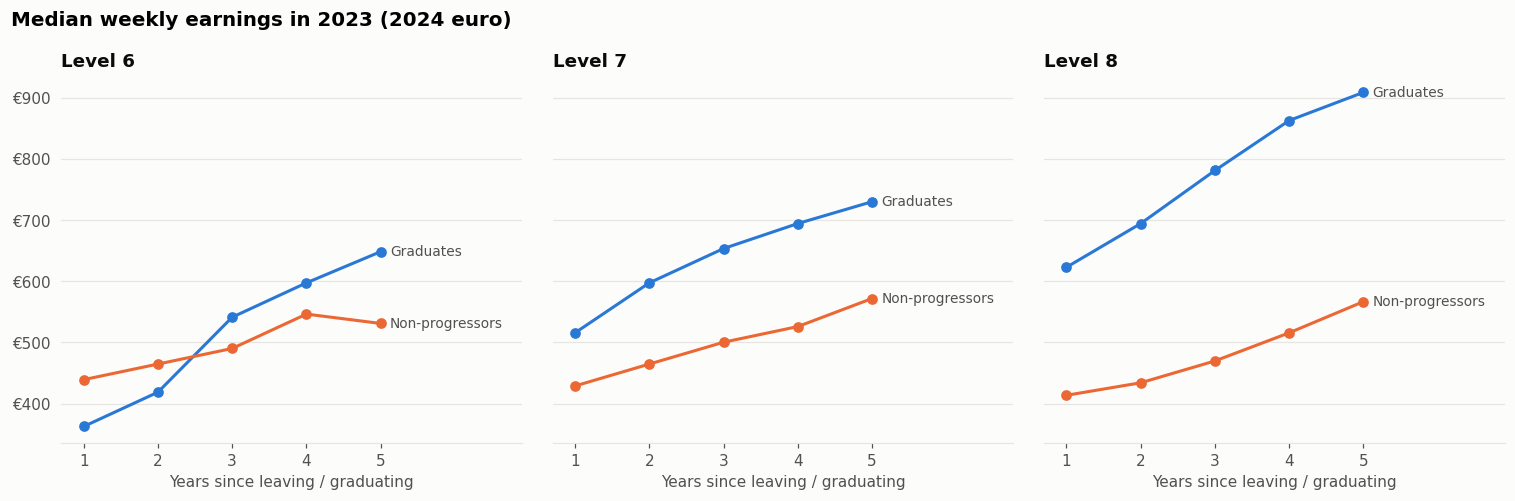

In [3]:
# Latest earnings year, medians side by side
lat = both[both.earnings_year == 2023]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
for ax, lv in zip(axes, LEVELS):
    d = lat[lat.nfq_level == lv].set_index("years_since").sort_index()
    ax.plot(d.index, d.p50_real_gr, marker="o", color=SERIES[0])
    ax.plot(d.index, d.p50_real_np, marker="o", color=SERIES[1])
    label_end(ax, d.index[-1], d.p50_real_gr.iloc[-1], "Graduates")
    label_end(ax, d.index[-1], d.p50_real_np.iloc[-1], "Non-progressors")
    ax.set_title(lv.replace("NFQ ", ""), fontsize=12)
    ax.set_xlabel("Years since leaving / graduating"); ax.set_xticks(d.index)
    ax.set_xlim(0.7, d.index[-1] + 1.9)
axes[0].yaxis.set_major_formatter(EUR)
fig.suptitle("Median weekly earnings in 2023 (2024 euro)", x=0.01, ha="left", fontweight="bold", fontsize=13)
save(fig, "g1_np_vs_grad_2023")

nfq_level,NFQ Level 6,NFQ Level 7,NFQ Level 8
years_since,,,
1,1.147,0.836,0.648
2,0.999,0.763,0.605
3,0.910,0.763,0.592
4,0.885,0.767,0.598
5,0.819,0.783,0.624


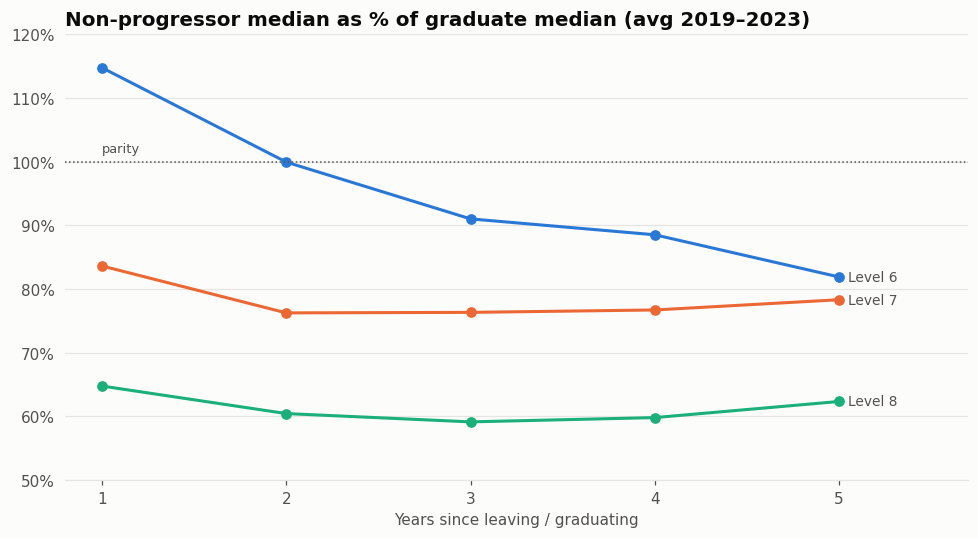

In [4]:
# Ratio over time: is the gap closing?
fig, ax = plt.subplots()
r = both.groupby(["nfq_level", "years_since"]).ratio.mean().unstack(0)
for i, lv in enumerate(LEVELS):
    ax.plot(r.index, r[lv], marker="o", color=SERIES[i])
    label_end(ax, r.index[-1], r[lv].iloc[-1], lv.replace("NFQ ", ""))
ax.axhline(1, color=INK2, lw=1, ls=":")
ax.text(1, 1.01, "parity", fontsize=8.5, color=INK2, va="bottom")
ax.set_title("Non-progressor median as % of graduate median (avg 2019–2023)")
ax.set_xlabel("Years since leaving / graduating"); ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0.5, 1.2); ax.set_xticks(r.index); ax.set_xlim(0.8, r.index[-1] + 0.7)
save(fig, "g2_ratio_by_years")
r.round(3)

- **Level 8 (honours degree):** non-progressors earn **≈60% of graduate pay** — €210–350/week less in 2024 euro — and the ratio is flat over five years. The gap does **not** close.
- **Level 7 (ordinary degree):** ≈75–85%, also flat.
- **Level 6 (higher certificate):** non-progressors are **ahead** in year 1 (they've been working ~1 year longer than new L6 graduates) but are level by year 2 and fall behind from year 3, to ≈82–91%.

In [5]:
# Euro gap, level 8, latest year
both[(both.nfq_level == "NFQ Level 8") & (both.earnings_year == 2023)][
    ["years_since", "p50_real_np", "p50_real_gr", "gap_eur", "ratio"]].round(2)

,years_since,p50_real_np,p50_real_gr,gap_eur,ratio
51,5,566.8,909.0,342.2,0.62
99,4,515.8,863.0,347.2,0.60
135,3,469.8,781.3,311.5,0.60
161,2,434.1,694.5,260.4,0.63
175,1,413.6,623.0,209.4,0.66


## 2. Same years since starting college
Shift graduates forward by course length − 1 so both groups are the same number of years from entry.

In [6]:
rows = []
for lv, L in COURSE_YEARS.items():
    a = np_[(np_.gender == "All genders") & (np_.nfq_level == lv)].copy()
    a["since_entry"] = a.years_since + 1          # left after year 1
    b = gr_[(gr_.gender == "All genders") & (gr_.nfq_level == lv)].copy()
    b["since_entry"] = b.years_since + L          # graduated after L years
    rows.append(a.merge(b, on=["earnings_year", "since_entry", "nfq_level"], suffixes=("_np", "_gr")))
e = pd.concat(rows)
e["ratio"] = e.p50_real_np / e.p50_real_gr
tab = e.pivot_table(index="since_entry", columns="nfq_level", values="ratio").round(2)
tab

nfq_level,NFQ Level 6,NFQ Level 7,NFQ Level 8
since_entry,,,
3,1.24,NaN,NaN
4,1.08,0.96,NaN
5,0.98,0.90,0.83
6,0.89,0.87,0.82


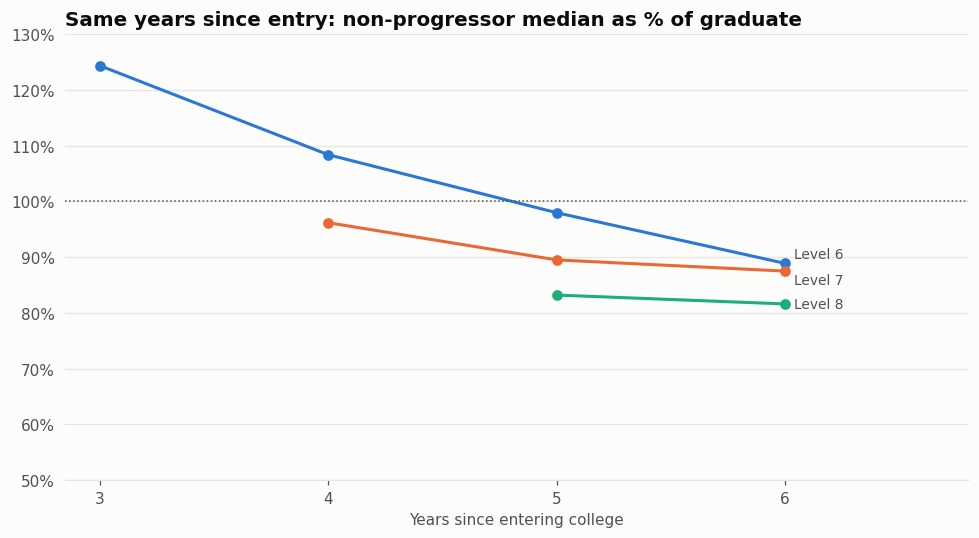

In [7]:
fig, ax = plt.subplots()
for i, lv in enumerate(LEVELS):
    s = e[e.nfq_level == lv].groupby("since_entry").ratio.mean()
    ax.plot(s.index, s.values, marker="o", color=SERIES[i])
    label_end(ax, s.index[-1], s.values[-1], lv.replace("NFQ ", ""), dy={"NFQ Level 6": 6, "NFQ Level 7": -6}.get(lv, 0))
ax.axhline(1, color=INK2, lw=1, ls=":")
ax.set_xticks(sorted(e.since_entry.unique()))
ax.set_title("Same years since entry: non-progressor median as % of graduate")
ax.set_xlabel("Years since entering college"); ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0.5, 1.3); ax.set_xlim(None, e.since_entry.max() + 0.8)
save(fig, "g3_ratio_since_entry")

Even with **3 extra years of work experience**, Level 8 non-progressors earn only ≈82–83% of a brand-new
honours graduate from the same entry cohort. Level 6 non-progressors start ahead (124%) but drop below parity by year 5–6. This is the clearest sign that the gap is not just about time in the labour market.

## 3. Gender

In [8]:
gg = m[(m.gender.isin(["Male", "Female"]))].groupby(["nfq_level", "gender"]).ratio.mean().unstack().round(3)
gg

gender,Female,Male
nfq_level,,
NFQ Level 6,0.968,1.013
NFQ Level 7,0.779,0.769
NFQ Level 8,0.600,0.627


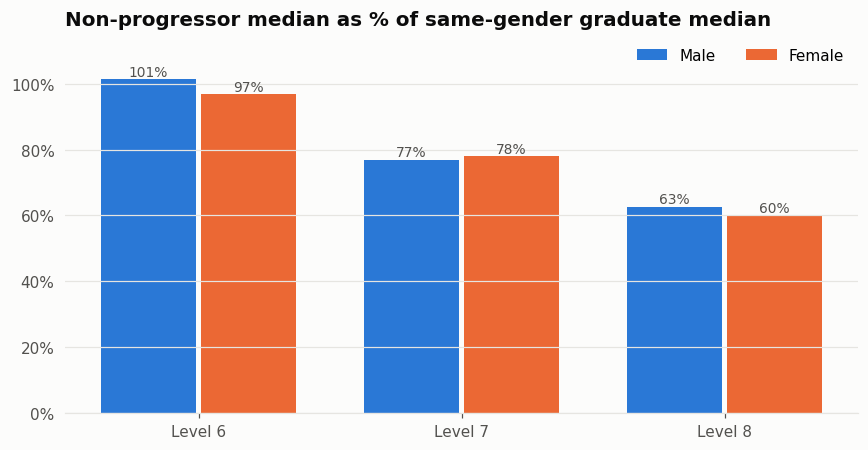

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(LEVELS)); w = 0.36
GCOL = {"Male": SERIES[0], "Female": SERIES[1]}  # same entity colours as notebook 01
for i, gname in enumerate(["Male", "Female"]):
    v = gg.loc[LEVELS, gname]
    ax.bar(x + (i - 0.5) * (w + 0.02), v, width=w, color=GCOL[gname], label=gname)
    for xi, vi in zip(x, v): ax.text(xi + (i - 0.5) * (w + 0.02), vi + 0.01, f"{vi:.0%}", ha="center", fontsize=9, color=INK2)
ax.set_xticks(x, [l.replace("NFQ ", "") for l in LEVELS]); ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, 1.15); ax.legend(loc="upper right", ncols=2)
ax.set_title("Non-progressor median as % of same-gender graduate median")
save(fig, "g4_ratio_gender")

## Summary

| | Level 6 | Level 7 | Level 8 |
|---|---|---|---|
| NP / graduate median, same years since leaving | ≈ 0.8–1.15 (ahead in year 1, behind from year 3) | ≈ 0.75–0.85 | ≈ **0.60** |
| Gap closing over 5 years? | No — widens | No — flat | No — flat |

**Interpretation (descriptive, not causal):** the largest earnings gap is for people who leave honours-degree (L8) courses,
and it persists. Selection matters — people who don't progress differ from graduates in many ways (prior attainment,
circumstances, field) — so this is the *observed* gap, not the causal return to finishing.

**Caveats**
- HEO12 graduates at L6/L7 may include people who continued to a higher level; NPO13 "All NFQ Levels" covers only L6–8,
  so this notebook compares **level by level**, never the "All" rows.
- Earnings are weekly and mix full-/part-time; graduates in further study are included in HEO12 counts if employed.
- Course lengths in section 2 are typical values, not exact.
- Earnings-year alignment assumes "N years since" = cohort year + N for both tables.